<a href="https://colab.research.google.com/github/Giocrisrai/aprendizaje-refuerzo-duoc/blob/main/notebooks/08_neuroevolucion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# 08 · Neuroevolución
**Machine Learning — Duoc UC**

Una red no se entrena aquí con gradiente. Se sortean pesos, se mide cuánto se equivoca la red, y los pesos buenos se cruzan y se les suma un poco de ruido. Eso es neuroevolución. NEAT, además, deja crecer la arquitectura. En esta clase la red es fija, de 2 entradas, 6 neuronas ocultas y 1 salida, para que el XOR quepa en la hora.

| Entradas | Salida que queremos |
|---|---|
| 0, 0 | 0 |
| 0, 1 | 1 |
| 1, 0 | 1 |
| 1, 1 | 0 |

Una recta no separa esas cuatro filas. Por eso hay capa oculta. CartPole, el caminante y el aterrizaje del diplomado son el mismo algoritmo con otro ambiente y muchos más minutos; no hacen falta para ver la idea.


In [1]:
#@title ⚙️ Configuración (ejecutar primero — en Colab clona el repositorio, sin subir archivos)
import os, sys, subprocess, glob

REPO_URL = "https://github.com/Giocrisrai/aprendizaje-refuerzo-duoc"
EN_COLAB = "google.colab" in sys.modules
ARCHIVOS = ("rl_utils.py", "salmon_env.py", "grilla.py", "evolucion.py")
DATOS = (
    "../data/runs_cliffwalking.csv",
    "../data/historial_inventario.csv",
    "../data/historial_operador_salmon.csv",
)

def buscar_notebooks():
    """Carpeta que contiene los .py de la clase, o None."""
    if all(os.path.exists(nombre) for nombre in ARCHIVOS):
        return os.getcwd()
    candidatos = [
        "/content/aprendizaje-refuerzo-duoc/notebooks",
        "/content/rl_aprendizaje_refuerzo/notebooks",
    ]
    candidatos += glob.glob("/content/**/notebooks", recursive=True)
    vistos = []
    for carpeta in candidatos:
        if carpeta in vistos or not os.path.isdir(carpeta):
            continue
        vistos.append(carpeta)
        if all(os.path.exists(os.path.join(carpeta, nombre)) for nombre in ARCHIVOS):
            return carpeta
    return None

if EN_COLAB and buscar_notebooks() is None:
    subprocess.run(
        ["git", "clone", "-q", "--depth", "1", REPO_URL, "/content/aprendizaje-refuerzo-duoc"],
        check=False,
    )

carpeta = buscar_notebooks()
if carpeta is None:
    raise FileNotFoundError(
        "No encuentro " + ", ".join(ARCHIVOS) + ". "
        "En Colab esta celda clona el repositorio: ahí están los módulos y data/. "
        "En el computador, abre el notebook desde la carpeta notebooks/."
    )
os.chdir(carpeta)

if EN_COLAB:
    req = os.path.abspath(os.path.join(os.getcwd(), "..", "requirements.txt"))
    if os.path.exists(req):
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", req])
try:
    import numpy, pandas, matplotlib
except ImportError as exc:
    raise ImportError("Faltan numpy, pandas o matplotlib. En local, desde la raíz del repositorio: uv sync --group dev") from exc
faltan = [ruta for ruta in DATOS if not os.path.exists(ruta)]
if faltan:
    raise FileNotFoundError("Faltan datos del repositorio: " + ", ".join(faltan))
print("✅ Listo. Carpeta de trabajo:", os.getcwd(), "| Colab" if EN_COLAB else "| local")
print("Librerías:", "numpy", numpy.__version__, "| pandas", pandas.__version__, "| matplotlib", matplotlib.__version__)


✅ Listo. Carpeta de trabajo: /Users/giocrisraigodoy/Documents/DUOC/2026-2/rl_clase/notebooks | local


exactitud: 1.0
(0, 0) → 0.091
(0, 1) → 0.793
(1, 0) → 0.916
(1, 1) → 0.144


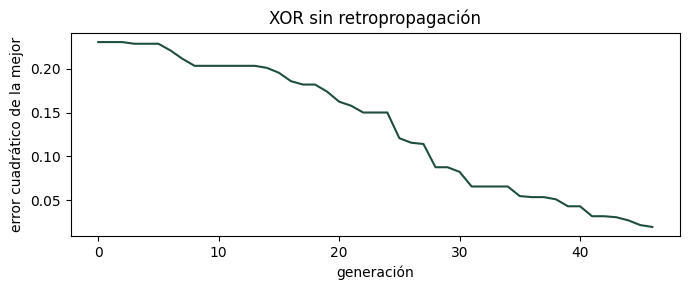

In [2]:
import matplotlib.pyplot as plt
from evolucion import evolucionar_xor

pesos, exactitud, pred, historia = evolucionar_xor(semilla=1)
print("exactitud:", exactitud)
for entradas, p in zip([(0, 0), (0, 1), (1, 0), (1, 1)], pred):
    print(entradas, "→", round(float(p), 3))

plt.figure(figsize=(7, 3))
plt.plot(historia, color="#1f4e3d")
plt.xlabel("generación")
plt.ylabel("error cuadrático de la mejor")
plt.title("XOR sin retropropagación")
plt.tight_layout()
plt.show()


## Ejercicio
Con umbral 0,5, una predicción cuenta como 1 si pasa el umbral. La exactitud es la fracción de filas correctas.


In [3]:
def exactitud_umbral(pred, objetivos, umbral=0.5):
    raise NotImplementedError("completa esta función")


In [4]:
import numpy as np

try:
    assert exactitud_umbral([0.1, 0.9, 0.8, 0.2], [0, 1, 1, 0]) == 1
    assert exactitud_umbral([0.6, 0.4, 0.4, 0.6], [0, 1, 1, 0]) == 0
    print("✅ Umbral 0,5. La red de arriba quedó en", exactitud)
except NotImplementedError:
    print("Pendiente: completa exactitud_umbral.")
except AssertionError:
    print("La primera lista, cortada en 0,5, da 0,1,1,0. Las cuatro coinciden.")


Pendiente: completa exactitud_umbral.


In [5]:
#@title 💡 Solución ejercicio (doble clic para ver el código)
import numpy as np

def exactitud_umbral(pred, objetivos, umbral=0.5):
    pred = np.asarray(pred, dtype=float) > umbral
    objetivos = np.asarray(objetivos, dtype=float)
    return float(np.mean(pred == objetivos))


## Cierre de las dos unidades
La grilla se resolvió con una tabla (notebook 01), con una ruta evolutiva (06), se podría escribir como una expresión (07) y, si el estado fueran píxeles, con una red como esta. El centro de salmón del notebook 05 está en el primer caso: observan cuatro números, diseñan el estado, y la tabla se puede mostrar en la defensa.

Lo que no cambia entre las cuatro es cómo se informa. Semillas, una línea base, y el retorno al final, no el de un episodio suelto. Eso está en el notebook 02.

### Qué es ejemplo y qué es tarea
El XOR que aprende solo es el ejemplo. `exactitud_umbral` es la tarea.

Un minuto con el resultado, sin la explicación: [NEAT resolviendo XOR](https://www.youtube.com/watch?v=G-yjV7KaWog). La clase donde se explica el método: [Evolutionary Robotics, lecture 16, NEAT](https://www.youtube.com/watch?v=-bWBCpZxmxU) (inglés).
